# Notebook 8: Field-Weighted Citation Impact (FWCI)
Field-weighted citation impact (FWCI) is a [Snowball Metric](https://www.elsevier.com/insights/metrics/snowball-metrics) that quantifies citation performance relative to publications from the same field and publication year. It is a normalized metric that accounts for differences in citations across different years (and fields; but here all articles are from the same field), making it a more appropriate metric for comparing citation performance than raw citation counts.
<br><br>
Like in Notebook #7, we will compare FWCI between *sharing* and *non-sharing* articles, and then across the three sharing granularities (FIXATION, TRIAL, PARTICIPANT). The analysis is run at two steps: First, we use a uni-variate approach (t-test or Mann-Whitney U test, depending on normality). Second, we fit a multivariable regression to test whether the findings hold when controlling for other known predictors of article impact (e.g., number of authors, open-access status, etc.). Note that because FWCI is already normalized for publication year, we do not include *publication age* as a covariate in the regression model.
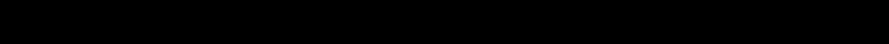
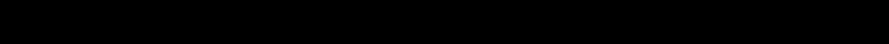
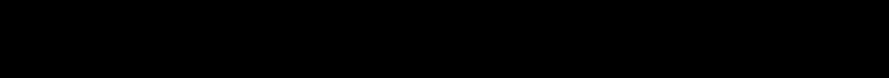

In [1]:
import numpy as np
import pandas as pd
import pingouin as pg
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

from helpers.config import *
from helpers import dataset
from helpers.stats import compare_continuous, granularity_wald_test, model_diagnostics, pairwise_contrasts, sharing_effect
from helpers.plotting import save_figure

pio.renderers.default = "browser"

## Setup

In [2]:
combined, FEATURES_DF = dataset.load_or_build()
FWCI_DF = (
    pd.concat([
        FEATURES_DF, combined["FieldWeightedCitationIndex"], np.log(dataset.fwci_with_zeros_imputed(combined))
    ], axis=1)
    .rename(columns={"FieldWeightedCitationIndex": "FWCI", "fwci_with_zeros_imputed": "log(Imputed FWCI)"})
    .drop(columns=["log(Weeks Since Pub.)"])
)
FWCI_DF = dataset.to_smf_columns(FWCI_DF)

FWCI_DF.columns

Loaded cached dataset from C:\Users\nirjo\Documents\University\PhD\Projects\eye_movement_data_sharing\data_store (234 rows)


Index(['is_sharing_data', 'sharing_class', 'has_us_author', 'is_open_access',
       'has_preprint', 'log_number_of_authors', 'venue_impact', 'venue_name',
       'fwci', 'log_imputed_fwci'],
      dtype='str')

## Sharing vs. Non-Sharing

In [3]:
GROUPING_VARIABLE = "is_sharing_data"

### Univariate Comparison

In [4]:
# compare summary statistics of citation counts between sharing and non-sharing articles
FWCI_DF.groupby(GROUPING_VARIABLE)["fwci"].describe().T

is_sharing_data,0,1
count,154.000000,80.000000
mean,1.279551,1.653171
std,1.183644,1.443364
min,0.000000,0.000000
25%,0.451875,0.511600
50%,0.920250,1.195050
75%,1.562150,2.492800
max,6.559600,5.727700


In [5]:
# check for normality
sw_share = stats.shapiro(FWCI_DF[FWCI_DF[GROUPING_VARIABLE] == 1]["fwci"])
print(f"Sharing Group is Normal:\t\t{'YES' if sw_share.pvalue > 0.05 else 'NO'} (W={sw_share.statistic :.3f}; p={sw_share.pvalue :.3f})")

sw_non_share = stats.shapiro(FWCI_DF[FWCI_DF[GROUPING_VARIABLE] == 0]["fwci"])
print(f"Non-Sharing Group is Normal:\t{'YES' if sw_non_share.pvalue > 0.05 else 'NO'} (W={sw_non_share.statistic :.3f}; p={sw_non_share.pvalue :.3f})")

if sw_share.pvalue > 0.05 and sw_non_share.pvalue > 0.05:
    print("Both groups are normally distributed, using t-test.")
else:
    print("At least one group is not normally distributed, using Mann-Whitney U test.")

Sharing Group is Normal:		NO (W=0.880; p=0.000)
Non-Sharing Group is Normal:	NO (W=0.833; p=0.000)
At least one group is not normally distributed, using Mann-Whitney U test.


In [6]:
# run univariate test
fwci_univariate_test_results, citations_univariate_summary = compare_continuous(
    data=FWCI_DF,
    share_feature=GROUPING_VARIABLE,
    tested_feature="fwci",
    alternative="greater",
    verbose=False
)
fwci_univariate_test_results = pd.Series(fwci_univariate_test_results).rename("fwci")
is_significant = fwci_univariate_test_results.loc["p_val"] < 0.05

print(f"Univariate test is {'' if is_significant else 'NOT '}significant ({fwci_univariate_test_results.loc['test']}={fwci_univariate_test_results.loc['statistic']:.3f}, p={fwci_univariate_test_results.loc['p_val']:.4f})")

fwci_univariate_test_results

Univariate test is significant (MW_U=6999.000, p=0.0439)


test                                                         MW_U
alternative                                               greater
statistic                                                  6999.0
p_val                                                    0.043902
effect_sizes    {'rank-biserial': 0.1362012987012987, 'CLES': ...
Name: fwci, dtype: object

### Multivariable Regression
We compare *sharing* vs. *non-sharing* articles while controlling for other known predictors of citation impact. We use four different models, varying in the way they account for the venue of publication:
- Model 0 is an OLS regression with no venue term, with standard errors clustered by venue.
- Model 1 is an OLS regression, using the venue impact score as a predictor.
- Model 2 is a mixed-effects model (LME), with venue as a random effect.
- Model 3 merges the two approaches, using a LME with venue impact as a fixed effect and venue as a random effect. This is the most conservative model.

Models 0 and 3 **bracket** the sharing estimate rather than one superseding the other, because venue's causal role is not identified by these data (see Model 0 below).

#### Model 0 :: OLS without Venue
Model 0 omits the venue term entirely, so any sharing-venue-citation association is absorbed into the sharing coefficient rather than partialled out. Articles in the same venue are correlated, which a plain OLS ignores, so the standard errors are clustered by venue (with the small-sample correction and a *t* distribution on *G - 1* degrees of freedom, as there are only 23 venues).<br>
What the `is_sharing` coefficient *means* depends on a causal direction this corpus cannot settle:
- If sharing **leads to** publication in higher-impact venues, venue is a **mediator**, Model 0 estimates the total association, and Model 3 estimates the direct one.
- If instead a journal's data policy **drives** whether its authors share, venue is a **confounder**, Model 0 is confounded upward, and Model 3 is the estimate of interest.

The second reading is not far-fetched: sharing rates run from 0% (*Visual Cognition*, *Journal of Eye Movement Research*) to 82% (*PLoS ONE*), a spread that looks more like editorial policy than author choice. We therefore report Model 0 as a bound rather than as the preferred estimate, and do not interpret the gap between Models 0 and 3 as a mediated effect.
<br><br>
The model is specified as follows:
$$ log(\text{Imputed FWCI}) \sim 1 + C(\text{Sharing Status}) + C(\text{Is OA}) + C(\text{Has US Author}) + C(\text{Has Preprint}) + log(\text{Number of Authors}) $$

In [7]:
model0 = smf.ols(
    f"log_imputed_fwci ~ C({GROUPING_VARIABLE}) + C(has_us_author) + C(is_open_access) + C(has_preprint) + log_number_of_authors",
    data=FWCI_DF,
).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(FWCI_DF["venue_name"])[0], "use_correction": True}, use_t=True,
)

model0.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:       log_imputed_fwci   R-squared:                       0.057
Model:                            OLS   Adj. R-squared:                  0.036
Method:                 Least Squares   F-statistic:                     4.399
Date:                Wed, 14 Oct 2026   Prob (F-statistic):            0.00630
Time:                        09:29:32   Log-Likelihood:                -334.68
No. Observations:                 234   AIC:                             681.4
Df Residuals:                     228   BIC:                             702.1
Df Model:                           5                                         
Covariance Type:              cluster                                         
===========================================================================================
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  -0.8047      0.296     -2.720      0.012      -1.418      -0.191
C(is_sharing_data)[T.1]     0.1716      0.128      1.338      0.194      -0.094       0.437
C(has_us_author)[T.1]       0.3159      0.120      2.623      0.016       0.066       0.566
C(is_open_access)[T.1]      0.3425      0.209      1.637      0.116      -0.091       0.776
C(has_preprint)[T.1]        0.2229      0.161      1.383      0.181      -0.111       0.557
log_number_of_authors       0.1436      0.169      0.850      0.404      -0.207       0.494
==============================================================================
Omnibus:                        8.866   Durbin-Watson:                   2.028
Prob(Omnibus):                  0.012   Jarque-Bera (JB):                9.311
Skew:                          -0.476   Prob(JB):                      0.00951
Kurtosis:                       2.780   Cond. No.                         8.40
==============================================================================

Notes:
[1] Standard Errors are robust to cluster correlation (cluster)
"""

#### Model 1 :: OLS with Venue Impact
Model 1 uses venue impact scores as a covariate, and does not account for the venue of publication as a random effect. The model is specified as follows:
$$ log(\text{Imputed FWCI}) \sim 1 + C(\text{Sharing Status}) + C(\text{Is OA}) + C(\text{Has US Author}) + C(\text{Has Preprint}) + log(\text{Number of Authors}) + \text{Impact Score} $$

In [8]:
model1 = smf.ols(
    f"log_imputed_fwci ~ C({GROUPING_VARIABLE}) + C(has_us_author) + C(is_open_access) + C(has_preprint) + log_number_of_authors + venue_impact",
    data=FWCI_DF,
    drop_cols=["sharing_class"]
).fit()

model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:       log_imputed_fwci   R-squared:                       0.085
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     3.530
Date:                Wed, 14 Oct 2026   Prob (F-statistic):            0.00232
Time:                        09:29:32   Log-Likelihood:                -331.12
No. Observations:                 234   AIC:                             676.2
Df Residuals:                     227   BIC:                             700.4
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
===========================================================================================
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  -1.0752      0.271     -3.972      0.000      -1.609      -0.542
C(is_sharing_data)[T.1]     0.0925      0.150      0.615      0.539      -0.204       0.389
C(has_us_author)[T.1]       0.2938      0.134      2.186      0.030       0.029       0.559
C(is_open_access)[T.1]      0.3858      0.189      2.043      0.042       0.014       0.758
C(has_preprint)[T.1]        0.1975      0.173      1.140      0.256      -0.144       0.539
log_number_of_authors       0.0918      0.158      0.580      0.563      -0.220       0.404
venue_impact                0.1437      0.054      2.650      0.009       0.037       0.251
==============================================================================
Omnibus:                        7.298   Durbin-Watson:                   2.056
Prob(Omnibus):                  0.026   Jarque-Bera (JB):                7.580
Skew:                          -0.433   Prob(JB):                       0.0226
Kurtosis:                       2.833   Cond. No.                         14.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

#### Model 2 :: Mixed-Effects
Model 2 uses venue as a random effect, and does not include the venue impact score as a covariate. The model is specified as follows:
$$ log(\text{Imputed FWCI}) \sim 1 + C(\text{Sharing Status}) + C(\text{Is OA}) + C(\text{Has US Author}) + C(\text{Has Preprint}) + log(\text{Number of Authors}) + (1 | \text{Venue}) $$

In [9]:
model2 = smf.mixedlm(
    f"log_imputed_fwci ~ C({GROUPING_VARIABLE}) + C(has_us_author) + C(is_open_access) + C(has_preprint) + log_number_of_authors",
    data=FWCI_DF,
    groups=FWCI_DF["venue_name"],
    drop_cols=["sharing_class"]
).fit(reml=True)

model2.summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
              Mixed Linear Model Regression Results
==================================================================
Model:              MixedLM  Dependent Variable:  log_imputed_fwci
No. Observations:   234      Method:              REML            
No. Groups:         23       Scale:               0.9691          
Min. group size:    1        Log-Likelihood:      -337.4228       
Max. group size:    43       Converged:           Yes             
Mean group size:    10.2                                          
------------------------------------------------------------------
                        Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------------
Intercept               -0.752    0.281 -2.674 0.007 -1.304 -0.201
C(is_sharing_data)[T.1]  0.119    0.156  0.763 0.445 -0.186  0.424
C(has_us_author)[T.1]    0.264    0.134  1.968 0.049  0.001  0.527
C(is_open_access)[T.1]   0.382    0.212  1.799 0.072 -0.034  0.797
C(has_preprint)[T.1]     0.113    0.174  0.647 0.518 -0.229  0.454
log_number_of_authors    0.150    0.158  0.946 0.344 -0.161  0.460
Group Var                0.086    0.064                           
==================================================================

"""

#### Model 3 :: Mixed-Effects with Venue Impact
Model 3 uses venue as a random effect, and includes the venue impact score as a covariate. The model is specified as follows:
$$ log(\text{Imputed FWCI}) \sim 1 + C(\text{Sharing Status}) + C(\text{Is OA}) + C(\text{Has US Author}) + C(\text{Has Preprint}) + log(\text{Number of Authors}) + \text{Impact Score} + (1 | \text{Venue}) $$

In [10]:
model3 = smf.mixedlm(
    f"log_imputed_fwci ~ C({GROUPING_VARIABLE}) + C(has_us_author) + C(is_open_access) + C(has_preprint) + log_number_of_authors + venue_impact",
    data=FWCI_DF,
    groups=FWCI_DF["venue_name"],
    drop_cols=["sharing_class"]
).fit(reml=True)

model3.summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
              Mixed Linear Model Regression Results
==================================================================
Model:              MixedLM  Dependent Variable:  log_imputed_fwci
No. Observations:   234      Method:              REML            
No. Groups:         23       Scale:               0.9493          
Min. group size:    1        Log-Likelihood:      -335.8767       
Max. group size:    43       Converged:           Yes             
Mean group size:    10.2                                          
------------------------------------------------------------------
                        Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------------
Intercept               -1.155    0.321 -3.599 0.000 -1.784 -0.526
C(is_sharing_data)[T.1]  0.066    0.154  0.432 0.666 -0.235  0.368
C(has_us_author)[T.1]    0.244    0.133  1.843 0.065 -0.016  0.504
C(is_open_access)[T.1]   0.373    0.209  1.783 0.075 -0.037  0.782
C(has_preprint)[T.1]     0.106    0.172  0.620 0.535 -0.230  0.443
log_number_of_authors    0.106    0.158  0.671 0.502 -0.203  0.415
venue_impact             0.193    0.079  2.461 0.014  0.039  0.347
Group Var                0.076    0.056                           
==================================================================

"""

### Model Selection
We compare the four models above to see how the venue term (none, the venue impact score as a covariate, venue as a random effect, or both) affects convergence and explained variance.<br>
We also check whether the estimated effect of sharing on FWCI - on the log scale, so `exp(b) - 1` is the proportional difference in FWCI - is consistent across the four models. We report Model 0 (the total association) beside Model 3 (the venue-adjusted one).


In [11]:
MODELS = {"0: OLS (no venue)": model0, "1: OLS": model1, "2: LME (venue)": model2, "3: LME (venue + impact)": model3}

# compare model diagnostics:
diagnostics = pd.DataFrame({name: model_diagnostics(res) for name, res in MODELS.items()}).T
diagnostics.index.name = "Model"

print(f"Best r^2 (marginal) is {diagnostics['R2 marginal'].max():.3f} in model {diagnostics['R2 marginal'].idxmax()}")
print(f"Best r^2 (conditional) is {diagnostics['R2 conditional'].max():.3f} in model {diagnostics['R2 conditional'].idxmax()}")
diagnostics

Best r^2 (marginal) is 0.093 in model 3: LME (venue + impact)
Best r^2 (conditional) is 0.160 in model 3: LME (venue + impact)


,converged,N,R2 marginal,R2 conditional,ICC
Model,,,,,
0: OLS (no venue),n/a,234,0.057043,0.057043,NaN
1: OLS,n/a,234,0.085342,0.085342,NaN
2: LME (venue),True,234,0.04286,0.120485,0.081101
3: LME (venue + impact),True,234,0.093172,0.160482,0.074226


In [12]:
# compare sharing effects across models
SHARING_TERM = "C(is_sharing_data)[T.1]"
sharing_effects = pd.DataFrame({name: sharing_effect(res, SHARING_TERM) for name, res in MODELS.items()}).T

same_sign = sharing_effects["b"].gt(0).all() or sharing_effects["b"].lt(0).all()
ci_includes_zero = (sharing_effects["CI low"] < 0).all() and (sharing_effects["CI high"] > 0).all()
print(f"Sharing coefficient ranges from {sharing_effects['b'].min():.3f} to {sharing_effects['b'].max():.3f} across models")
print(f"Same sign in all {len(MODELS)} models: {'YES' if same_sign else 'NO'}")
print(f"95% CI includes 0 in all {len(MODELS)} models: {'YES' if ci_includes_zero else 'NO'}")

sharing_effects

Sharing coefficient ranges from 0.066 to 0.172 across models
Same sign in all 4 models: YES
95% CI includes 0 in all 4 models: YES


,b,SE,p,CI low,CI high,% diff,% diff CI low,% diff CI high
0: OLS (no venue),0.171559,0.128201,0.194498,-0.094314,0.437431,18.715392,-9.000279,54.872390
1: OLS,0.092472,0.150390,0.539246,-0.203866,0.388810,9.688284,-18.442805,47.522482
2: LME (venue),0.118844,0.155718,0.445345,-0.186358,0.424046,12.619412,-17.002398,52.813234
3: LME (venue + impact),0.066479,0.153924,0.665815,-0.235205,0.368164,6.873888,-20.959152,44.507912


---


## Sharing Granularity


In [13]:
GROUPING_VARIABLE = "sharing_class"

FWCI_GRANULARITY_DF = FWCI_DF.loc[FWCI_DF[GROUPING_VARIABLE] != "NONE"]
FWCI_GRANULARITY_DF[GROUPING_VARIABLE] = FWCI_GRANULARITY_DF[GROUPING_VARIABLE].cat.remove_unused_categories()

# verify we are left only with the three sharing classes
FWCI_GRANULARITY_DF[GROUPING_VARIABLE].unique()


['FIXATION', 'TRIAL', 'PARTICIPANT']
Categories (3, str): ['PARTICIPANT' < 'TRIAL' < 'FIXATION']

### Univariate Comparison


In [14]:
# compare summary statistics of FWCI between sharing granularities
FWCI_GRANULARITY_DF.groupby(GROUPING_VARIABLE)["fwci"].describe().T


sharing_class,PARTICIPANT,TRIAL,FIXATION
count,23.000000,26.000000,31.000000
mean,1.675813,1.243019,1.980371
std,1.181175,1.178515,1.746042
min,0.104200,0.000000,0.185400
25%,0.614050,0.431900,0.678200
50%,1.576300,0.783150,1.302100
75%,2.637950,1.686975,2.496000
max,4.348700,3.906200,5.727700


In [15]:
all_normal = True
for sg in FWCI_GRANULARITY_DF[GROUPING_VARIABLE].unique():
    # check for normality
    sw = stats.shapiro(
        FWCI_GRANULARITY_DF[FWCI_GRANULARITY_DF[GROUPING_VARIABLE] == sg]["fwci"]
    )
    sw_p = sw.pvalue
    print(f"{sg} Sharing Group is Normal:\t{'YES' if sw_p > 0.05 else 'NO'} (W={sw.statistic :.3f}; p={sw_p :.3f})")
    all_normal &= sw_p > 0.05

print()
print(f"All sharing groups are normally distributed: {'YES' if all_normal else 'NO'}")
print(f"Using {'ANOVA' if all_normal else 'Kruskal-Wallis'} test for group comparisons.")


FIXATION Sharing Group is Normal:	NO (W=0.832; p=0.000)
TRIAL Sharing Group is Normal:	NO (W=0.842; p=0.001)
PARTICIPANT Sharing Group is Normal:	YES (W=0.939; p=0.175)

All sharing groups are normally distributed: NO
Using Kruskal-Wallis test for group comparisons.


In [16]:
# run univariate test
fwci_granularity_results, _fwci_granularity_summary = compare_continuous(
    data=FWCI_GRANULARITY_DF,
    share_feature=GROUPING_VARIABLE,
    tested_feature="fwci",
    alternative="two-sided",
    verbose=False
)
fwci_granularity_results = pd.Series(fwci_granularity_results).rename("fwci")
is_significant = fwci_granularity_results.loc["p_val"] < 0.05

print(f"Univariate test is {'' if is_significant else 'NOT '}significant ({fwci_granularity_results.loc['test']}={fwci_granularity_results.loc['statistic']:.3f}, p={fwci_granularity_results.loc['p_val']:.4f})")

fwci_granularity_results


Univariate test is NOT significant (KW=3.082, p=0.2142)


test                                           KW
statistic                                3.081666
p_val                                    0.214203
dof                                             2
effect_sizes    {'epsilon2': 0.03900843002489198}
Name: fwci, dtype: object

### Multivariable Regression
We compare the three sharing granularities while controlling for other known predictors of citation impact.<br>
We use the same four models as above, varying in the way they account for the venue of publication:

#### Model 0 :: OLS without Venue (standard errors clustered by venue)
$$ log(\text{Imputed FWCI}) \sim 1 + C(\text{Sharing Granularity}) + C(\text{Is OA}) + C(\text{Has US Author}) + C(\text{Has Preprint}) + log(\text{Number of Authors}) $$

#### Model 1 :: OLS
$$ log(\text{Imputed FWCI}) \sim 1 + C(\text{Sharing Granularity}) + C(\text{Is OA}) + C(\text{Has US Author}) + C(\text{Has Preprint}) + log(\text{Number of Authors}) + \text{Impact Score} $$

#### Model 2 :: Mixed-Effects
$$ log(\text{Imputed FWCI}) \sim 1 + C(\text{Sharing Granularity}) + C(\text{Is OA}) + C(\text{Has US Author}) + C(\text{Has Preprint}) + log(\text{Number of Authors}) + (1 | \text{Venue}) $$

#### Model 3 :: Mixed-Effects with Venue Impact
$$ log(\text{Imputed FWCI}) \sim 1 + C(\text{Sharing Granularity}) + C(\text{Is OA}) + C(\text{Has US Author}) + C(\text{Has Preprint}) + log(\text{Number of Authors}) + \text{Impact Score} + (1 | \text{Venue}) $$


In [17]:
gran_model0 = smf.ols(
    f"log_imputed_fwci ~ C({GROUPING_VARIABLE}) + C(has_us_author) + C(is_open_access) + C(has_preprint) + log_number_of_authors",
    data=FWCI_GRANULARITY_DF,
).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(FWCI_GRANULARITY_DF["venue_name"])[0], "use_correction": True}, use_t=True,
)

gran_model0.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:       log_imputed_fwci   R-squared:                       0.133
Model:                            OLS   Adj. R-squared:                  0.062
Method:                 Least Squares   F-statistic:                     2.320
Date:                Wed, 14 Oct 2026   Prob (F-statistic):             0.0753
Time:                        09:29:37   Log-Likelihood:                -112.94
No. Observations:                  80   AIC:                             239.9
Df Residuals:                      73   BIC:                             256.6
Df Model:                           6                                         
Covariance Type:              cluster                                         
================================================================================================
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept                       -0.4480      0.536     -0.836      0.414      -1.570       0.674
C(sharing_class)[T.TRIAL]       -0.0447      0.220     -0.203      0.841      -0.505       0.416
C(sharing_class)[T.FIXATION]     0.3764      0.256      1.468      0.158      -0.160       0.913
C(has_us_author)[T.1]            0.6572      0.243      2.708      0.014       0.149       1.165
C(is_open_access)[T.1]           0.0421      0.566      0.074      0.941      -1.142       1.226
C(has_preprint)[T.1]            -0.1556      0.202     -0.770      0.451      -0.579       0.267
log_number_of_authors            0.1108      0.277      0.399      0.694      -0.470       0.692
==============================================================================
Omnibus:                        2.415   Durbin-Watson:                   1.886
Prob(Omnibus):                  0.299   Jarque-Bera (JB):                2.398
Skew:                          -0.397   Prob(JB):                        0.302
Kurtosis:                       2.703   Cond. No.                         11.2
==============================================================================

Notes:
[1] Standard Errors are robust to cluster correlation (cluster)
"""

In [18]:
gran_model1 = smf.ols(
    f"log_imputed_fwci ~ C({GROUPING_VARIABLE}) + C(has_us_author) + C(is_open_access) + C(has_preprint) + log_number_of_authors + venue_impact",
    data=FWCI_GRANULARITY_DF,
).fit()

gran_model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:       log_imputed_fwci   R-squared:                       0.185
Model:                            OLS   Adj. R-squared:                  0.106
Method:                 Least Squares   F-statistic:                     2.333
Date:                Wed, 14 Oct 2026   Prob (F-statistic):             0.0333
Time:                        09:29:37   Log-Likelihood:                -110.49
No. Observations:                  80   AIC:                             237.0
Df Residuals:                      72   BIC:                             256.0
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
================================================================================================
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept                       -1.0795      0.605     -1.784      0.079      -2.286       0.127
C(sharing_class)[T.TRIAL]       -0.0158      0.324     -0.049      0.961      -0.662       0.630
C(sharing_class)[T.FIXATION]     0.4761      0.306      1.557      0.124      -0.133       1.085
C(has_us_author)[T.1]            0.6446      0.251      2.567      0.012       0.144       1.145
C(is_open_access)[T.1]           0.2351      0.446      0.527      0.600      -0.655       1.125
C(has_preprint)[T.1]            -0.2093      0.247     -0.849      0.399      -0.701       0.282
log_number_of_authors           -0.0174      0.301     -0.058      0.954      -0.618       0.583
venue_impact                     0.2146      0.101      2.132      0.036       0.014       0.415
==============================================================================
Omnibus:                        2.178   Durbin-Watson:                   2.052
Prob(Omnibus):                  0.337   Jarque-Bera (JB):                2.161
Skew:                          -0.349   Prob(JB):                        0.339
Kurtosis:                       2.599   Cond. No.                         21.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [19]:
gran_model2 = smf.mixedlm(
    f"log_imputed_fwci ~ C({GROUPING_VARIABLE}) + C(has_us_author) + C(is_open_access) + C(has_preprint) + log_number_of_authors",
    data=FWCI_GRANULARITY_DF,
    groups=FWCI_GRANULARITY_DF["venue_name"],
).fit(reml=True)

gran_model2.summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                 Mixed Linear Model Regression Results
=======================================================================
Model:               MixedLM    Dependent Variable:    log_imputed_fwci
No. Observations:    80         Method:                REML            
No. Groups:          20         Scale:                 1.0294          
Min. group size:     1          Log-Likelihood:        -115.9194       
Max. group size:     15         Converged:             Yes             
Mean group size:     4.0                                               
-----------------------------------------------------------------------
                             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------------------
Intercept                    -0.495    0.556 -0.890 0.374 -1.585  0.595
C(sharing_class)[T.TRIAL]    -0.029    0.330 -0.089 0.929 -0.676  0.617
C(sharing_class)[T.FIXATION]  0.391    0.314  1.248 0.212 -0.223  1.006
C(has_us_author)[T.1]         0.645    0.258  2.501 0.012  0.140  1.150
C(is_open_access)[T.1]        0.128    0.464  0.276 0.782 -0.781  1.038
C(has_preprint)[T.1]         -0.193    0.254 -0.759 0.448 -0.691  0.305
log_number_of_authors         0.107    0.300  0.356 0.722 -0.481  0.695
Group Var                     0.054    0.087                           
=======================================================================

"""

In [20]:
gran_model3 = smf.mixedlm(
    f"log_imputed_fwci ~ C({GROUPING_VARIABLE}) + C(has_us_author) + C(is_open_access) + C(has_preprint) + log_number_of_authors + venue_impact",
    data=FWCI_GRANULARITY_DF,
    groups=FWCI_GRANULARITY_DF["venue_name"],
).fit(reml=True)

gran_model3.summary()

C:\Users\nirjo\Documents\University\PhD\Projects\eye_movement_data_sharing\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\nirjo\Documents\University\PhD\Projects\eye_movement_data_sharing\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
C:\Users\nirjo\Documents\University\PhD\Projects\eye_movement_data_sharing\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


<class 'statsmodels.iolib.summary2.Summary'>
"""
                 Mixed Linear Model Regression Results
=======================================================================
Model:               MixedLM    Dependent Variable:    log_imputed_fwci
No. Observations:    80         Method:                REML            
No. Groups:          20         Scale:                 1.0301          
Min. group size:     1          Log-Likelihood:        -115.4059       
Max. group size:     15         Converged:             Yes             
Mean group size:     4.0                                               
-----------------------------------------------------------------------
                             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------------------
Intercept                    -1.079    0.606 -1.782 0.075 -2.267  0.108
C(sharing_class)[T.TRIAL]    -0.016    0.324 -0.049 0.961 -0.651  0.619
C(sharing_class)[T.FIXATION]  0.476    0.307  1.548 0.122 -0.127  1.079
C(has_us_author)[T.1]         0.645    0.252  2.561 0.010  0.151  1.138
C(is_open_access)[T.1]        0.235    0.450  0.523 0.601 -0.647  1.117
C(has_preprint)[T.1]         -0.209    0.248 -0.844 0.398 -0.695  0.277
log_number_of_authors        -0.017    0.303 -0.057 0.954 -0.611  0.577
venue_impact                  0.215    0.104  2.071 0.038  0.012  0.418
Group Var                     0.000    0.055                           
=======================================================================

"""

### Model Selection


In [21]:
GRAN_MODELS = {"0: OLS (no venue)": gran_model0, "1: OLS": gran_model1, "2: LME (venue)": gran_model2, "3: LME (venue + impact)": gran_model3}

In [22]:
# compare model diagnostics:
gran_diagnostics = pd.DataFrame({name: model_diagnostics(res) for name, res in GRAN_MODELS.items()}).T
gran_diagnostics.index.name = "Model"

print(f"Best r^2 (marginal) is {gran_diagnostics['R2 marginal'].max():.3f} in model {gran_diagnostics['R2 marginal'].idxmax()}")
print(f"Best r^2 (conditional) is {gran_diagnostics['R2 conditional'].max():.3f} in model {gran_diagnostics['R2 conditional'].idxmax()}")
gran_diagnostics

Best r^2 (marginal) is 0.185 in model 1: OLS
Best r^2 (conditional) is 0.185 in model 1: OLS


,converged,N,R2 marginal,R2 conditional,ICC
Model,,,,,
0: OLS (no venue),n/a,80,0.133448,0.133448,NaN
1: OLS,n/a,80,0.184886,0.184886,NaN
2: LME (venue),True,80,0.124492,0.168459,0.050219
3: LME (venue + impact),True,80,0.169491,0.169648,0.00019


In [23]:
# the two coefficients are each class vs. the PARTICIPANT baseline
GRAN_TERMS = ["C(sharing_class)[T.TRIAL]", "C(sharing_class)[T.FIXATION]"]
gran_sharing_effects = pd.DataFrame(
    {(name, term): sharing_effect(res, term) for name, res in GRAN_MODELS.items() for term in GRAN_TERMS}
).T
gran_sharing_effects.index.names = ["Model", "Term"]
gran_sharing_effects

b        SE  \
Model                   Term                                               
0: OLS (no venue)       C(sharing_class)[T.TRIAL]    -0.044689  0.219948   
                        C(sharing_class)[T.FIXATION]  0.376439  0.256363   
1: OLS                  C(sharing_class)[T.TRIAL]    -0.015844  0.324122   
                        C(sharing_class)[T.FIXATION]  0.476103  0.305696   
2: LME (venue)          C(sharing_class)[T.TRIAL]    -0.029234  0.329966   
                        C(sharing_class)[T.FIXATION]  0.391199  0.313507   
3: LME (venue + impact) C(sharing_class)[T.TRIAL]    -0.015836  0.324133   
                        C(sharing_class)[T.FIXATION]  0.475990  0.307429   

                                                             p    CI low  \
Model                   Term                                               
0: OLS (no venue)       C(sharing_class)[T.TRIAL]     0.841155 -0.505046   
                        C(sharing_class)[T.FIXATION]  0.158361 -0.160134   
1: OLS                  C(sharing_class)[T.TRIAL]     0.961148 -0.661970   
                        C(sharing_class)[T.FIXATION]  0.123751 -0.133291   
2: LME (venue)          C(sharing_class)[T.TRIAL]     0.929402 -0.675956   
                        C(sharing_class)[T.FIXATION]  0.212098 -0.223263   
3: LME (venue + impact) C(sharing_class)[T.TRIAL]     0.961035 -0.651124   
                        C(sharing_class)[T.FIXATION]  0.121551 -0.126559   

                                                       CI high     % diff  \
Model                   Term                                                
0: OLS (no venue)       C(sharing_class)[T.TRIAL]     0.415668  -4.370518   
                        C(sharing_class)[T.FIXATION]  0.913013  45.708731   
1: OLS                  C(sharing_class)[T.TRIAL]     0.630282  -1.571929   
                        C(sharing_class)[T.FIXATION]  1.085497  60.978888   
2: LME (venue)          C(sharing_class)[T.TRIAL]     0.617488  -2.881087   
                        C(sharing_class)[T.FIXATION]  1.005662  47.875341   
3: LME (venue + impact) C(sharing_class)[T.TRIAL]     0.619453  -1.571079   
                        C(sharing_class)[T.FIXATION]  1.078539  60.960732   

                                                      % diff CI low  \
Model                   Term                                          
0: OLS (no venue)       C(sharing_class)[T.TRIAL]        -39.652229   
                        C(sharing_class)[T.FIXATION]     -14.797063   
1: OLS                  C(sharing_class)[T.TRIAL]        -48.416599   
                        C(sharing_class)[T.FIXATION]     -12.478994   
2: LME (venue)          C(sharing_class)[T.TRIAL]        -49.133014   
                        C(sharing_class)[T.FIXATION]     -20.009527   
3: LME (venue + impact) C(sharing_class)[T.TRIAL]        -47.854086   
                        C(sharing_class)[T.FIXATION]     -11.887751   

                                                      % diff CI high  
Model                   Term                                          
0: OLS (no venue)       C(sharing_class)[T.TRIAL]          51.538286  
                        C(sharing_class)[T.FIXATION]      149.181954  
1: OLS                  C(sharing_class)[T.TRIAL]          87.814007  
                        C(sharing_class)[T.FIXATION]      196.091227  
2: LME (venue)          C(sharing_class)[T.TRIAL]          85.426423  
                        C(sharing_class)[T.FIXATION]      173.371512  
3: LME (venue + impact) C(sharing_class)[T.TRIAL]          85.791209  
                        C(sharing_class)[T.FIXATION]      194.038087

### Pairwise Contrasts
Comparing all three granularities against each other: each contrast is the second level minus the first (`TRIAL vs. PARTICIPANT` is the TRIAL coefficient, `FIXATION vs. TRIAL` is the difference between the two coefficients). `t` is a z statistic in the mixed-effects models. `p_FDR` is Benjamini-Hochberg across the three contrasts of each model. `ratio` is `exp(b)`, the ratio of the geometric means, and `% change` is `ratio - 1`.

In [24]:
gran_contrasts = pd.concat(
    {name: pairwise_contrasts(res, GRAN_TERMS, baseline="PARTICIPANT") for name, res in GRAN_MODELS.items()}, names=["Model"],
)
gran_contrasts

b        SE  \
Model                   Contrast                                       
0: OLS (no venue)       TRIAL vs. PARTICIPANT    -0.044689  0.219948   
                        FIXATION vs. PARTICIPANT  0.376439  0.256363   
                        FIXATION vs. TRIAL        0.421128  0.355116   
1: OLS                  TRIAL vs. PARTICIPANT    -0.015844  0.324122   
                        FIXATION vs. PARTICIPANT  0.476103  0.305696   
                        FIXATION vs. TRIAL        0.491947  0.292578   
2: LME (venue)          TRIAL vs. PARTICIPANT    -0.029234  0.329966   
                        FIXATION vs. PARTICIPANT  0.391199  0.313507   
                        FIXATION vs. TRIAL        0.420433  0.298354   
3: LME (venue + impact) TRIAL vs. PARTICIPANT    -0.015836  0.324133   
                        FIXATION vs. PARTICIPANT  0.475990  0.307429   
                        FIXATION vs. TRIAL        0.491826  0.294656   

                                                         t         p  \
Model                   Contrast                                       
0: OLS (no venue)       TRIAL vs. PARTICIPANT    -0.203180  0.841155   
                        FIXATION vs. PARTICIPANT  1.468385  0.158361   
                        FIXATION vs. TRIAL        1.185890  0.250285   
1: OLS                  TRIAL vs. PARTICIPANT    -0.048883  0.961148   
                        FIXATION vs. PARTICIPANT  1.557438  0.123751   
                        FIXATION vs. TRIAL        1.681424  0.097014   
2: LME (venue)          TRIAL vs. PARTICIPANT    -0.088597  0.929402   
                        FIXATION vs. PARTICIPANT  1.247818  0.212098   
                        FIXATION vs. TRIAL        1.409177  0.158783   
3: LME (venue + impact) TRIAL vs. PARTICIPANT    -0.048855  0.961035   
                        FIXATION vs. PARTICIPANT  1.548296  0.121551   
                        FIXATION vs. TRIAL        1.669155  0.095087   

                                                     p_FDR     ratio  \
Model                   Contrast                                       
0: OLS (no venue)       TRIAL vs. PARTICIPANT     0.841155  0.956295   
                        FIXATION vs. PARTICIPANT  0.375428  1.457087   
                        FIXATION vs. TRIAL        0.375428  1.523680   
1: OLS                  TRIAL vs. PARTICIPANT     0.961148  0.984281   
                        FIXATION vs. PARTICIPANT  0.185627  1.609789   
                        FIXATION vs. TRIAL        0.185627  1.635498   
2: LME (venue)          TRIAL vs. PARTICIPANT     0.929402  0.971189   
                        FIXATION vs. PARTICIPANT  0.318147  1.478753   
                        FIXATION vs. TRIAL        0.318147  1.522621   
3: LME (venue + impact) TRIAL vs. PARTICIPANT     0.961035  0.984289   
                        FIXATION vs. PARTICIPANT  0.182327  1.609607   
                        FIXATION vs. TRIAL        0.182327  1.635299   

                                                   % change  
Model                   Contrast                             
0: OLS (no venue)       TRIAL vs. PARTICIPANT     -4.370518  
                        FIXATION vs. PARTICIPANT  45.708731  
                        FIXATION vs. TRIAL        52.368002  
1: OLS                  TRIAL vs. PARTICIPANT     -1.571929  
                        FIXATION vs. PARTICIPANT  60.978888  
                        FIXATION vs. TRIAL        63.549773  
2: LME (venue)          TRIAL vs. PARTICIPANT     -2.881087  
                        FIXATION vs. PARTICIPANT  47.875341  
                        FIXATION vs. TRIAL        52.262146  
3: LME (venue + impact) TRIAL vs. PARTICIPANT     -1.571079  
                        FIXATION vs. PARTICIPANT  60.960732  
                        FIXATION vs. TRIAL        63.529916

#### Omnibus Test
Running a Wald test to determine if the granularity coefficients differ from zero, jointly. This is a more stringent test than the per-coefficient or per-contrast results reported above, because it tests the null hypothesis that all granularity coefficients are zero simultaneously, rather than testing each coefficient individually.

In [25]:
gran_omnibus = pd.DataFrame({name: granularity_wald_test(res, GRAN_TERMS) for name, res in GRAN_MODELS.items()}).T
n_significant = int((gran_omnibus["p"] < 0.05).sum())
print(f"Omnibus p-value ranges from {gran_omnibus['p'].min():.3f} to {gran_omnibus['p'].max():.3f} across models")
print(f"Significant (p < 0.05) in {n_significant} of {len(gran_omnibus)} models")

gran_omnibus

Omnibus p-value ranges from 0.161 to 0.360 across models
Significant (p < 0.05) in 0 of 4 models


,test,statistic,p,df_denom,df_num
0: OLS (no venue),F,1.079186,0.359814,19,2
1: OLS,F,1.861699,0.162812,72,2
2: LME (venue),chi2,2.509568,0.285137,2,None
3: LME (venue + impact),chi2,3.655129,0.160805,2,None


In [26]:
1/0

ZeroDivisionError: division by zero

### (1) FWCI
#### (1A) Sharing / Non-Sharing Articles

In [ ]:
not_sharing_fwci = combined.loc[~combined["is_sharing_data"], "FieldWeightedCitationIndex"]
sharing_fwci = combined.loc[combined["is_sharing_data"], "FieldWeightedCitationIndex"]

# check normality of FWCI distributions:
print("Is FWCI normally distributed for non-sharing articles?")
fwci_non_sharing_shapiro = stats.shapiro(not_sharing_fwci)
print(f"{"YES" if fwci_non_sharing_shapiro.pvalue > 0.05 else "NO"} (W={fwci_non_sharing_shapiro.statistic:.3f}, p={fwci_non_sharing_shapiro.pvalue:.4f})\n")

print("Is FWCI normally distributed for sharing articles?")
fwci_sharing_shapiro = stats.shapiro(sharing_fwci)
print(f"{"YES" if fwci_sharing_shapiro.pvalue > 0.05 else "NO"} (W={fwci_sharing_shapiro.statistic:.3f}, p={fwci_sharing_shapiro.pvalue:.4f})")

In [ ]:
fwci_pair_test = stats.mannwhitneyu(not_sharing_fwci, sharing_fwci, alternative="less")

# calculate effect size (rank-biserial correlation / CLES)
n1, n2 = len(not_sharing_fwci), len(sharing_fwci)
U_nonshare = fwci_pair_test.statistic
U_share = n1 * n2 - U_nonshare
rank_biserial_corr = (U_share - U_nonshare) / (n1 * n2)
cles = U_share / (n1 * n2)

print("Share / Non-Share FWCI Comparison:")
print("Mann-Whitney U Test:" + f"\tU={fwci_pair_test.statistic},\tp={fwci_pair_test.pvalue:.4f}")
print("{0: <20}".format("Effect Sizes:") + f"\tRBC: {rank_biserial_corr:.3f}\tCLES: {cles:.3f}")

# re-run statistical test with `pingouin` for robustness:
pg.mwu(not_sharing_fwci, sharing_fwci, alternative="less")

#### (1B) Data Sharing Class

In [ ]:
# check normality of FWCI distributions for each sharing class:
share_group_fwci = []
for share_group in ["FIXATION", "TRIAL", "PARTICIPANT"]:
    group_fwci = (
        combined
        .loc[combined["data_sharing_class"] == share_group, "FieldWeightedCitationIndex"]
        .dropna()
        .reset_index(drop=True)
        .rename(share_group)
    )
    share_group_fwci.append(group_fwci)
    shapiro_result = stats.shapiro(group_fwci)
    print(f"Is FWCI normally distributed for {share_group} sharing articles?")
    print(f"{"YES" if shapiro_result.pvalue > 0.05 else "NO"} (W={shapiro_result.statistic:.3f}, p={shapiro_result.pvalue:.4f})\n")

# run Kruskal-Wallis H-test:
fwci_sharegroup_test = stats.kruskal(*share_group_fwci)
fwci_sharegroup_test

#### Visualizing Share/Non-Share FWCI Comparison

In [ ]:
suplot_titles = ["Sharing vs. Non-Sharing", "Different Types of Data Sharing"]
fwci_fig = make_subplots(
    rows=1, cols=len(suplot_titles), column_titles=suplot_titles,
    shared_yaxes=True, horizontal_spacing=0.025, vertical_spacing=0.025,
)

# (1) Sharing vs. Non-Sharing
left_subplot_data_long = (
    combined
    .melt(
        id_vars=['is_sharing_data'],
        value_vars=['FieldWeightedCitationIndex'],
        var_name='name',
        value_name='value'
    )
    .replace({
        'FieldWeightedCitationIndex': 'FWCI',
    })
)
max_y = left_subplot_data_long["value"].max()
for is_share in left_subplot_data_long["is_sharing_data"].unique():
    subset = left_subplot_data_long[left_subplot_data_long["is_sharing_data"] == is_share]
    subset_name = 'Sharing' if is_share else 'Not Sharing'
    color = CLASS_COLORS[subset_name.upper()]
    fwci_fig.add_trace(
        row=1, col=1,
        trace=go.Violin(
            x=subset['name'], y=subset['value'],
            name=subset_name, legendgroup=subset_name, scalegroup=subset_name,
            side='positive' if is_share else 'negative',
            fillcolor=color, line_color=color,
            width=0.9, spanmode="hard",
            points=False, pointpos=0, jitter=0.5,
            box=dict(visible=False, width=0.5, line=dict(color="black")),
            meanline=dict(visible=False, color='black'),
        )
    )
    # annotate half-violin
    fwci_fig.add_annotation(
        row=1, col=1,
        text=subset_name, font={**AXIS_TITLE_FONT, "color": color},
        x=0.25 if is_share else -0.2, xanchor="center", xref="x",
        y=0.925 * max_y, yanchor="middle", yref="paper",
        showarrow=False,
    )

# add significance asterisk
fwci_fig.add_annotation(
    row=1, col=1,
    x="FWCI", xanchor="center", xref="x",
    y=max_y * 1.05, yanchor="middle", yref="paper",
    text="*", font=TITLE_FONT, font_size=30,
    showarrow=False,
)
# add separation line
fwci_fig.add_shape(
    row=1, col=1,
    type="line", line=dict(color="black", width=2, dash="dash"),
    x0="FWCI", x1="FWCI", y0=0, y1=max_y,
)

# (2) Data Sharing Class
right_subplot_data_long = (
    combined
    .loc[combined["data_sharing_class"].isin(["FIXATION", "TRIAL", "PARTICIPANT"])]
    .melt(
        id_vars=['data_sharing_class'],
        value_vars=['FieldWeightedCitationIndex'],
        var_name='name',
        value_name='value'
    )
    .replace({
        'FieldWeightedCitationIndex': 'FWCI',
    })
)
for i, share_class in enumerate(right_subplot_data_long["data_sharing_class"].unique()):
    subset = right_subplot_data_long[right_subplot_data_long["data_sharing_class"] == share_class]
    color = CLASS_COLORS[share_class]
    fwci_fig.add_trace(
        row=1, col=2,
        trace=go.Violin(
            x=subset['data_sharing_class'], y=subset['value'],
            name=share_class, legendgroup=share_class, scalegroup=share_class,
            side='positive', points='all', pointpos=-0.25, jitter=0.2,
            fillcolor=color, line=dict(color=color, width=1.5),
            width=1.0, spanmode="hard",
            box=dict(visible=False, width=0.5, line=dict(color="gray")),
            meanline=dict(visible=False, color='gray'),
        ))
    # annotate half-violin
    fwci_fig.add_annotation(
        row=1, col=2,
        text=share_class.title(),
        font={**AXIS_TITLE_FONT, "color": color},
        x=i, xanchor="center", xref="x",
        y=0.925 * max_y, yanchor="middle", yref="paper",
        showarrow=False,
    )

# add n.s. mark
fwci_fig.add_annotation(
    row=1, col=2,
    x=1.0, xanchor="center", xref="x",
    y=max_y * 1.05, yanchor="middle", yref="paper",
    text="n.s.", font=TITLE_FONT,
    showarrow=False,
)


# update layout and show
for ann in fwci_fig.layout.annotations:
    if ann.text not in suplot_titles:
        continue
    ann_xref = 'x' if ann.text == suplot_titles[0] else 'x2'
    ann.update(dict(
        font=TITLE_FONT,
        x=-0.5, xanchor="left", xref=ann_xref,
        y=1.0, yanchor="top", yref="paper",
))
fwci_fig.update_xaxes(
    title=None, showticklabels=False, tickfont=AXIS_TICK_FONT, zeroline=False,
)
fwci_fig.update_yaxes(
    showgrid=True, gridcolor='lightgrey', gridwidth=1.5,
    zeroline=False,
)
fwci_fig.update_yaxes(
    row=1, col=1,
    range=[-0.5, max_y * 1.2],
    title=dict(text="<b>FWCI</b>", font=AXIS_TITLE_FONT, standoff=5),
    tickfont=AXIS_TICK_FONT,
)
fwci_fig.update_layout(
    width=1000, height=500,
    title=dict(
        text="<b>FWCI Distribution for Data Sharing Class</b>",
        font=TITLE_FONT,
        x=0.5, xanchor="center", y=0.95, yanchor="top"
    ),
    violinmode='overlay',
    violingap=0,
    legend=dict(visible=False,),
    margin=dict(t=50, b=5, l=50, r=10, pad=0),
    template="plotly_white",
)
fwci_fig.show()

In [ ]:
# flip to True to export this figure into `output/`
if False:
    save_figure(fwci_fig, "fwci_data_sharing.png", width=1000, height=500)

### Adjusting for Other Citation Predictors
Publication age is deliberately excluded from this model: OpenAlex normalizes FWCI by field,
publication year and document type, so age is accounted for by construction.

Venue is a different case. FWCI does **not** normalize it away, so venue impact remains a real
predictor here. It is left out of the model below on purpose: sharers publish in higher-impact
venues, which makes venue a plausible *mediator* of the sharing effect rather than a nuisance to
be partialled out. The model below is therefore the unadjusted estimate, and the venue-adjusted
estimate should be reported beside it, with the difference between the two read as mechanism.

In [ ]:
def build_fwci_model_df(combined: pd.DataFrame, features_df: pd.DataFrame) -> pd.DataFrame:
    """Feature matrix plus log1p FWCI, renamed for `smf.ols` via `dataset.to_smf_columns`.

    Age is excluded from the *covariates* below (not from this frame): FWCI already normalizes
    for field, publication year and document type. Venue impact is excluded for a different
    reason, as a plausible mediator rather than a confounder. See the markdown above.
    """
    log_fwci = np.log(combined["FieldWeightedCitationIndex"] + 1).rename("log(FWCI)")
    df = pd.concat([features_df, log_fwci], axis=1)
    return dataset.to_smf_columns(df)

fwci_model_df = build_fwci_model_df(combined, FEATURES_DF)

covariate_model = smf.ols(
    "log_fwci ~ is_sharing_data + is_open_access + has_preprint + has_us_author + log_number_of_authors",
    # log_weeks_since_pub is normalized into FWCI by design; venue_impact is left out as a
    # mediator, not because FWCI normalizes it (it does not)
    data=fwci_model_df,
).fit()

beta = covariate_model.params["is_sharing_data"]
ci_low, ci_high = covariate_model.conf_int().loc["is_sharing_data"]
print(
    f"\nData-sharing effect adjusted for author count, US authorship, open access, and pre-print publication"
    f"\n(publication age is normalized into FWCI by construction; venue impact is deliberately not adjusted for):"
    f"\n\tbeta = {beta:.3f}  (95% CI [{ci_low:.3f}, {ci_high:.3f}]),  p = {covariate_model.pvalues['is_sharing_data']:.3f}"
    f"\n\tmultiplicative citation advantage = exp(beta) = {np.exp(beta):.3f}× ({(np.exp(beta) - 1) * 100:+.1f}%)"
)
covariate_model.summary()